
# But du laboratoire

L'objectif est d'apprendre et mettre en pratique la lecture et l'écriture de fichiers.

# Travail

## Exercice 1 - Lecture/Ecriture d'un fichier texte

Cet exercice a pour but d'apprendre à manipuler des fichiers texte.

1. Créez un fichier texte appelé "exemple.txt" en mode écriture ('w') et sauver la chaine de charactère *txt*. Utilisez la syntaxe `f = open(...)`, et assurez-vous de refermer le fichier après l'écriture.
2. Lisez le contenu du fichier "exemple.txt" et affichez-le. Vous pouvez utiliser l'autre syntaxe (`with open(...) as f:`), qui est souvent préférable, car elle gère automatiquement la fermeture du fichier, même en cas d'erreur.
3. Ouvrez à nouveau le fichier "exemple.txt", cette fois en mode ajout ('a'). Ajoutez une nouvelle ligne de texte à la fin du fichier.
4. Répétez la lecture du contenu du fichier après l'ajout et affichez le résultat mis à jour.


In [40]:

### Votre code
txt = 'J\'étudie à la heig-vd\n'
txt += 'J\'apprends le langage de programmation Python\n'
txt += 'Je vais utiliser ce langage dans mes cours\n'

# methode 1
f = open('./exemple.txt', 'w')      # Ouverture du fichier, mode écriture
f.write(txt)     # Ecriture de contenu
f.close()   # Fermeture du fichier

# methode 2
with open('./exemple.txt', 'w') as f:   # Ouverture du fichier, mode écriture
    f.write(txt)     # Ecriture de contenu


with open('./exemple.txt', 'r') as f:   # Ouverture du fichier, mode lecture
    content_before = f.read()               # Lecture du contenu
    print('Contenu avant l\'ajout :\n'+ content_before)

with open('./exemple.txt', 'a') as f:   # Ouverture du fichier, mode ajout
    f.write('Quatrième ligne ajoutée.')     # Ajout de contenu

with open('./exemple.txt', 'r') as f:   # Ouverture du fichier, mode lecture
    content_after = f.read()                # Lecture du contenu
    print('\nContenu après l\'ajout :\n'+ content_after)

###

Contenu avant l'ajout :
J'étudie à la heig-vd
J'apprends le langage de programmation Python
Je vais utiliser ce langage dans mes cours


Contenu après l'ajout :
J'étudie à la heig-vd
J'apprends le langage de programmation Python
Je vais utiliser ce langage dans mes cours
Quatrième ligne ajoutée.


## Exercice 2 - Lecture d'un fichier csv

Le répertoire "./agro_data/" contient des données représentant les températures mesurées durant le mois de décembre 2023 dans plusieurs localités vaudoises (source : https://www.agrometeo.ch/meteorologie/). Chaque fichier, au format CSV, contient les mesures sur une localité donnée. Le fichier contient 2 colonnes, une représentant la date et l'heure, et une représentant la température. Vous allez devoir lire ces données, et en extraire certaines informations :

1. A l'aide d'une compréhension, listez les fichiers dans le dossier "./agro_data/", et filtrez-les pour ne garder que les fichiers dont l'extension est ".csv"
2. Parcourez la liste de fichier csv et mettez les informations suivantes dans un dictionnaire pour chaque fichier:
    * le nom de la localité
    * un numpy array de temperature
    * la temperature maximum
    * la temperature moyenne
    * une liste des dates
    * une liste des heures

exemple d'un dictionnaire:
```python
d = {
    'location' : 'Aigle'
    'temperature' : [4.6, 4.5, 4.6, ..., 3.9, 4.1, 4.2]
    'max_temp' : 12.9
    'min_temp' : -2.8
    'mean_temp' : 4.64
    'date': ['01.12.2023', '01.12.2023', '01.12.2023', '01.12.2023', '01.12.2023',..]
    'heure': ['00:00', '00:10', '00:20', '00:30', '00:40',...]
}
```

3. Constuire une liste de l'ensemble des dictionnaires
4. Faire un affichage de la temperature pour les 3 premières localités
5. Sauver votre liste de dictionnaire dans un fichier ´export.json´

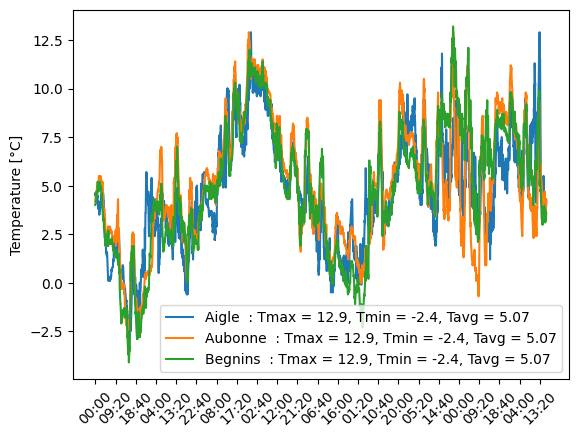

In [10]:
import json
import os
import numpy as np
import matplotlib.pyplot as plt


files = [f for f in os.listdir('./agro_data') if f.endswith('.csv')]

data = []

for file in files:
    location = file.split('.')[0]
    with open('./agro_data/'+file, 'r') as f:
        content = f.readlines()
        temperature = [float(line.split(';')[1]) for line in content[1:]]
        timestamp = [line.split(';')[0] for line in content[1:]]
        date = [t.split(' ')[0] for t in timestamp]
        heure = [t.split(' ')[1] for t in timestamp]

        
        loc_data = {}
        loc_data['location'] = location
        loc_data['temperature'] = temperature
        temp_np = np.asarray(temperature)
        loc_data['max_temp'] = np.max(temp_np)
        loc_data['min_temp'] = np.min(temp_np)
        loc_data['mean_temp'] = np.round(np.mean(temp_np),2)
        loc_data['date']  = date
        loc_data['heure'] = heure
        data.append(loc_data)


loc_idx = 1
data_loc = data[loc_idx]
step = 200

with open('export.json', 'w') as json_file:
    json.dump(data, json_file, indent=4)

plt.figure()


In [ ]:
for loc_data in data[:3]:
    plt.plot(loc_data['temperature'], label=f'{loc_data['location']}  : Tmax = {data_loc['max_temp']}, Tmin = {data_loc['min_temp']}, Tavg = {data_loc['mean_temp']}')
plt.xticks(range(0,len(data_loc['temperature']),step), data_loc['heure'][0:-1:step], rotation=45)
plt.ylabel('Temperature [°C]')
plt.legend()
plt.show()



## Exercice 3 - Lecture d'un fichier json

Le fichier que vous avez créé à l'exercice précédent contient des données météorologiques pour plusieurs localités.
Le but est de relire le fichier et d'afficher la temperature maximale de chaque localité

1. Lire le fichier ´export.json´ et le mettre dans une variable `new_data`
2. Afficher dans un bar plot les températures maximales, minimales et moyenne pour chaque localité


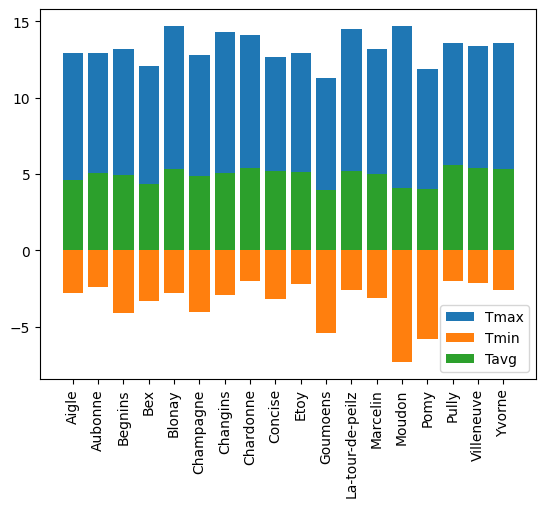

In [23]:
with open('export.json', 'r') as json_file:
    new_data = json.load(json_file)

temp_max = [loc_data['max_temp'] for loc_data in new_data]
temp_min = [loc_data['min_temp'] for loc_data in new_data]
temp_mean = [loc_data['mean_temp'] for loc_data in new_data]
localite = [loc_data['location'] for loc_data in new_data]
plt.figure()
plt.bar(localite, temp_max, label='Tmax')
plt.bar(localite, temp_min, label='Tmin')
plt.bar(localite, temp_mean, label='Tavg')
plt.legend()
plt.xticks(rotation=90)
plt.show()